# Free-space propagation: Fresnel, Rayleigh-Sommerfeld, Fraunhofer

This notebook illustrates the propagators in `pyoptics.propagators` with examples
whose physics is easy to follow: diffraction at a slit, a square and a circular
aperture, the Talbot effect, evanescent waves and the Poisson spot. Along the way
it covers the numerical issues on which FFT propagators can fail in practice:
sampling, cyclic convolution (wrap-around) and aliasing of the transfer function.

**Convention:** fields vary like $\exp(i(\mathbf{k}\cdot\mathbf{r} - \omega t))$.
A plane wave propagating by $z>0$ picks up the factor $\exp(+i k_z z)$,
evanescent waves decay like $\exp(-|k_z| z)$.

All lengths are in µm.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import fresnel, j1

from pyoptics import propagators as prop
from pyoptics.utils import grid1d, grid2d, freq_grid, wavenumber, k_z
from pyoptics.masks import circular_mask, rectangluar_mask
from pyoptics.analytical import mahajan_on_axis_intensity

plt.rcParams.update({"figure.dpi": 100, "image.origin": "lower", "font.size": 11,
                     "axes.grid": False})

wl = 0.5  # wavelength [µm]

## A helper: one-dimensional problems

The propagators work on 2D grids. For structures that are invariant in $y$
(slits, gratings), a grid with only two rows is enough: the field is constant in
$y$, so its spectrum only has the component $k_y = 0$. This makes it fast to
compute many $z$ planes and show them as an $xz$ image.

Important for all propagators: the grid must have $x = 0$ at index $N/2$, as
`grid1d(-L/2, L/2, N)` provides (the right end point is left out, matching the
periodicity of the FFT).

In [2]:
y_dummy = grid1d(-1, 1, 2)  # [-1, 0]: y = 0 at index N//2

def propagate_1d(propagator, u, x, z, wl, **kwargs):
    """Propagate a field u(x) that is invariant in y."""
    field = np.tile(u, (2, 1)).astype(complex)
    out, _, _ = propagator(field, x, y_dummy, z, wl, **kwargs)
    return out[0]

def xz_map(propagator, u, x, z_vals, wl, **kwargs):
    return np.array([propagate_1d(propagator, u, x, z, wl, **kwargs) for z in z_vals])

def plot_xz(ax, U, x, z_vals, title, xlim=None, vmax=None, cmap="inferno", zscale=1.0, zlabel="$z$ [µm]"):
    I = np.abs(U)**2
    im = ax.imshow(I, extent=(x[0], x[-1], z_vals[0]*zscale, z_vals[-1]*zscale), aspect="auto",
                   cmap=cmap, vmax=vmax, interpolation="bilinear")
    ax.set_xlabel("$x$ [µm]"); ax.set_ylabel(zlabel); ax.set_title(title)
    if xlim is not None:
        ax.set_xlim(*xlim)
    return im

## 1. Fresnel diffraction at a square aperture

A plane wave falls onto a square opening of half side length $a$. What the
diffraction pattern looks like is determined by the **Fresnel number** alone,

$$N_F = \frac{a^2}{\lambda z},$$

i.e. the number of Fresnel zones seen in the opening from the observation point.
For $N_F \gg 1$ one essentially sees the geometric shadow with diffraction
fringes; for $N_F \lesssim 1$ the pattern turns into Fraunhofer diffraction (far
field, $\mathrm{sinc}^2$).

In the Fresnel approximation there is an analytic solution in terms of the
Fresnel integrals $C$ and $S$:

$$U(x, y) = \frac{e^{ikz}}{2i}\, F(x)\, F(y), \qquad
  F(x) = \big[C(\beta)+iS(\beta)\big]_{\beta_1}^{\beta_2}, \quad
  \beta_{1,2} = \sqrt{\tfrac{2}{\lambda z}}\,(\mp a - x).$$

This allows a direct check of the numerics.

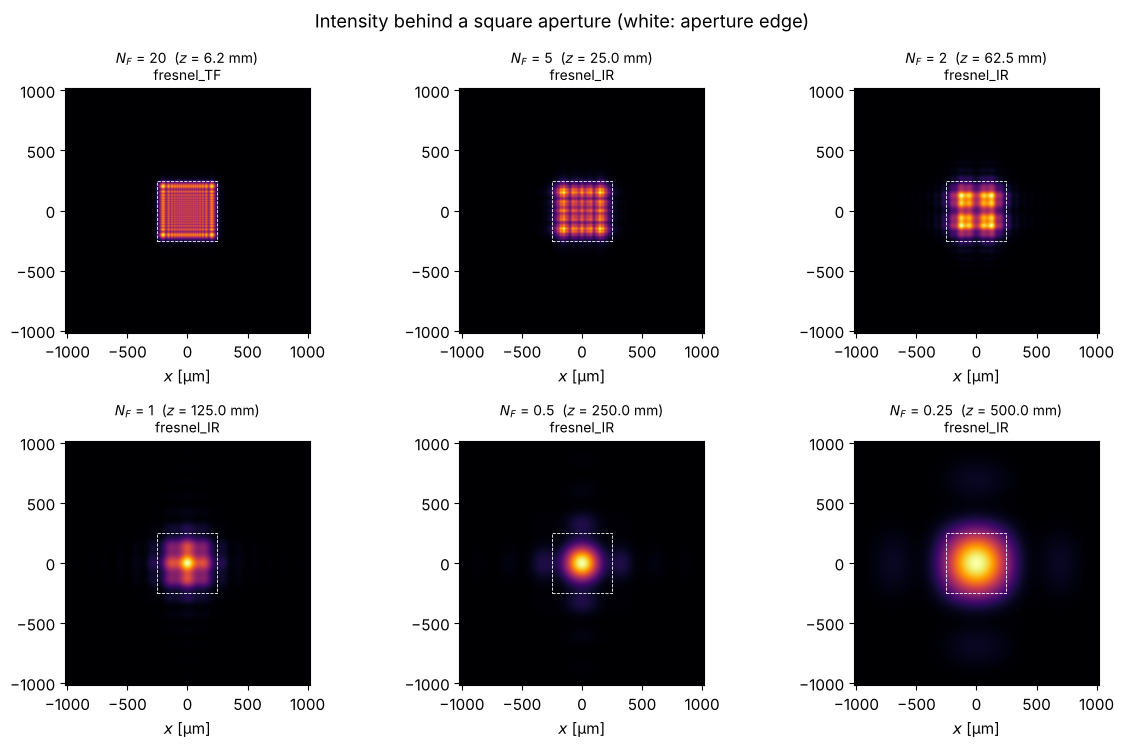

In [3]:
a = 250.0
# Choose the sampling distance such that the aperture edge lies exactly between
# two samples: then the discrete aperture is exactly 2a wide (at N_F = 20, an error
# of dx in the width already changes the phase of the edge waves by about 1 rad).
N = 1024
dx = 2*a/251
L = N*dx
x, y, X, Y = grid2d(-L/2, L/2, -L/2, L/2, N)
aperture = rectangluar_mask(x, y, a, a).astype(complex)

def fresnel_square_1d(x, z, a, wl):
    b1, b2 = np.sqrt(2/(wl*z))*(-a - x), np.sqrt(2/(wl*z))*(a - x)
    S1, C1 = fresnel(b1); S2, C2 = fresnel(b2)
    return (C2 - C1) + 1j*(S2 - S1)

NF_vals = [20, 5, 2, 1, 0.5, 0.25]
results = []
for NF in NF_vals:
    z = a**2/(wl*NF)
    # Transfer function (TF) or impulse response (IR)? The TF chirp is well sampled
    # for z < dx*L_pad/lambda, the IR for larger z (see Section 5):
    z_crit = dx*(2*L)/wl
    propagator = prop.fresnel_TF if z < z_crit else prop.fresnel_IR
    U, _, _ = prop.propagate_padded(propagator, aperture, x, y, z, wl, pad_factor=2)
    results.append((NF, z, U, propagator.__name__))

fig, axes = plt.subplots(2, 3, figsize=(12, 7.6))
for ax, (NF, z, U, name) in zip(axes.flat, results):
    ax.imshow(np.abs(U)**2, extent=(x[0], x[-1], y[0], y[-1]), cmap="inferno")
    ax.set_title(f"$N_F$ = {NF}  ($z$ = {z/1000:.1f} mm)\n{name}", fontsize=10)
    ax.set_xlabel("$x$ [µm]")
    ax.plot([-a, a, a, -a, -a], [-a, -a, a, a, -a], "w--", lw=0.6)
fig.suptitle("Intensity behind a square aperture (white: aperture edge)")
fig.tight_layout()

Cut at $y = 0$ compared with the analytic solution. At large Fresnel number, the
diffraction fringes at the edge of the geometric shadow are clearly visible; the
centre of the opening is almost undisturbed ($|U|^2 \approx 1$). The smaller
$N_F$, the more intensity is diffracted into the centre, until the far field
forms. For odd numbers of zones the centre is bright, for even numbers dark.

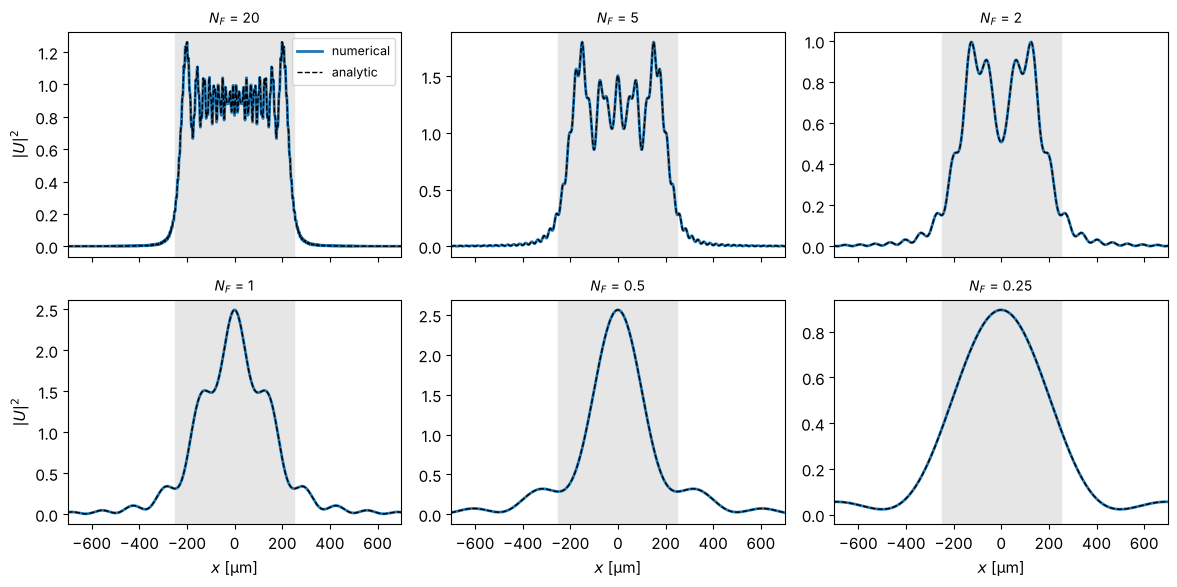

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharex=True)
for ax, (NF, z, U, name) in zip(axes.flat, results):
    F = fresnel_square_1d(x, z, a, wl)
    F0 = fresnel_square_1d(np.array([0.0]), z, a, wl)
    I_analytic = 0.25*np.abs(F)**2*np.abs(F0)**2  # cut at y = 0
    ax.plot(x, np.abs(U[N//2])**2, lw=2, label="numerical")
    ax.plot(x, I_analytic, "k--", lw=1, label="analytic")
    ax.axvspan(-a, a, color="0.9", zorder=-1)
    ax.set_title(f"$N_F$ = {NF}", fontsize=10)
    ax.set_xlim(-700, 700)
axes[0, 0].legend(fontsize=9)
for ax in axes[1]:
    ax.set_xlabel("$x$ [µm]")
for ax in axes[:, 0]:
    ax.set_ylabel("$|U|^2$")
fig.tight_layout()

The intensity in the centre as a function of the Fresnel number shows the
interplay of the Fresnel zones particularly clearly. For the square, the zones
are not circular rings; that is why the minimum does not drop all the way to zero.

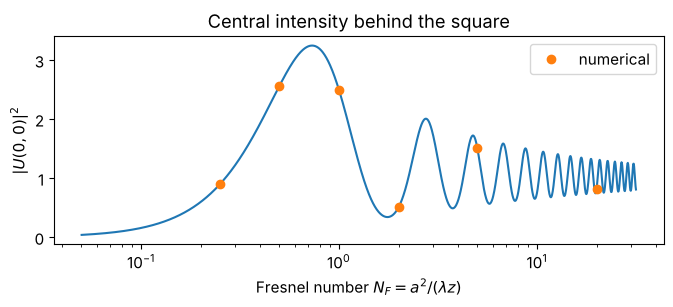

In [5]:
NF_cont = np.logspace(-1.3, 1.5, 1500)
I0 = [0.25*np.abs(fresnel_square_1d(np.array([0.0]), a**2/(wl*nf), a, wl))[0]**4 for nf in NF_cont]
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(NF_cont, I0)
ax.plot([r[0] for r in results], [np.abs(r[2][N//2, N//2])**2 for r in results], "o", label="numerical")
ax.set_xscale("log")
ax.set_xlabel("Fresnel number $N_F = a^2/(\\lambda z)$"); ax.set_ylabel("$|U(0,0)|^2$")
ax.set_title("Central intensity behind the square"); ax.legend()
fig.tight_layout()

## 2. The Talbot effect: self-imaging of periodic structures

A grating of period $d$ diffracts into the orders $k_x = 2\pi m/d$. In the
paraxial approximation, order $m$ picks up the phase $-\pi\lambda z m^2/d^2$
after a distance $z$. After the **Talbot length**

$$z_T = \frac{2 d^2}{\lambda}$$

all these phases are multiples of $2\pi$: the grating images itself. At $z_T/2$
it appears shifted by half a period, at $z_T/4$ with half the period. The result
is the well-known **Talbot carpet**.

Since the field is periodic, the cyclic FFT convolution is exactly right here and
no padding is needed. Comparing the paraxial Fresnel calculation with the exact
Rayleigh-Sommerfeld calculation shows that perfect self-imaging is a property of
the paraxial approximation: with $k_z = \sqrt{k^2 - k_x^2}$, the phases of the
high orders are no longer exactly commensurate and the carpet gradually blurs.

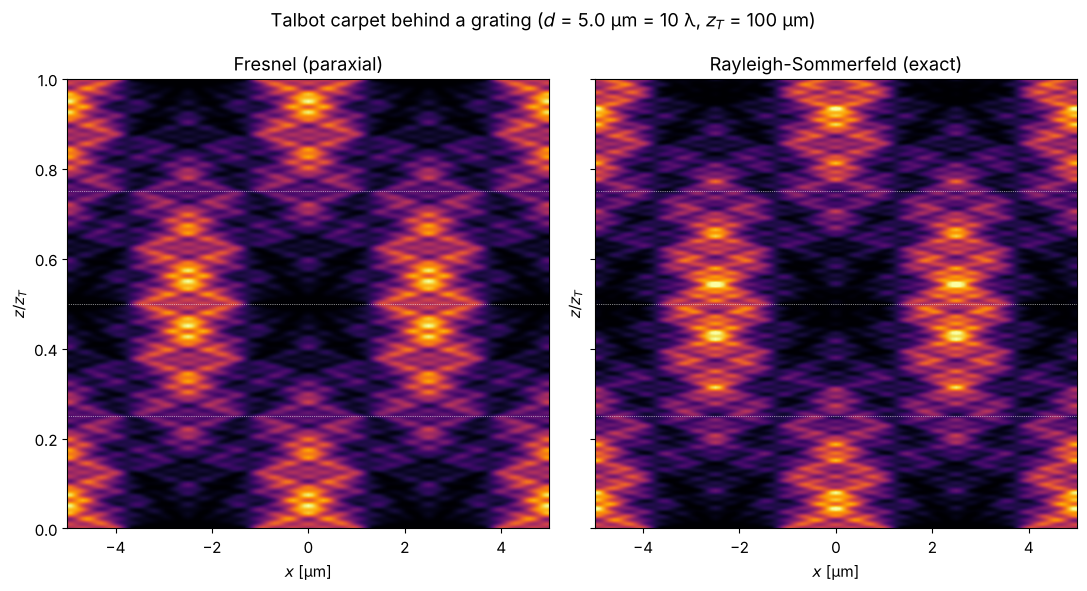

In [6]:
d = 5.0                   # grating period
z_T = 2*d**2/wl           # Talbot length
Lg, Ng = 8*d, 512
xg = grid1d(-Lg/2, Lg/2, Ng)
# Binary grating (duty cycle 1/2) whose Fourier series is truncated after the 7th
# order: all orders propagate (sin(theta_7) = 7 lambda/d = 0.7), but the higher ones
# are already clearly non-paraxial.
m_max = 7
grating = 0.5 + sum(2*np.sin(np.pi*m/2)/(np.pi*m)*np.cos(2*np.pi*m*xg/d) for m in range(1, m_max + 1))

z_vals = np.linspace(0, 1.0*z_T, 600)
carpet_F = xz_map(prop.fresnel_TF, grating, xg, z_vals, wl)
carpet_RS = xz_map(prop.rayleigh_sommerfeld_I_TF, grating, xg, z_vals, wl)

fig, axes = plt.subplots(1, 2, figsize=(11, 6), sharey=True)
for ax, U, title in zip(axes, (carpet_F, carpet_RS), ("Fresnel (paraxial)", "Rayleigh-Sommerfeld (exact)")):
    plot_xz(ax, U, xg, z_vals, title, xlim=(-d, d), vmax=2.0, zscale=1/z_T, zlabel="$z / z_T$")
    for frac in (0.25, 0.5, 0.75):
        ax.axhline(frac, color="w", lw=0.5, ls=":")
fig.suptitle(f"Talbot carpet behind a grating ($d$ = {d} µm = {d/wl:.0f} λ, $z_T$ = {z_T:.0f} µm)")
fig.tight_layout()

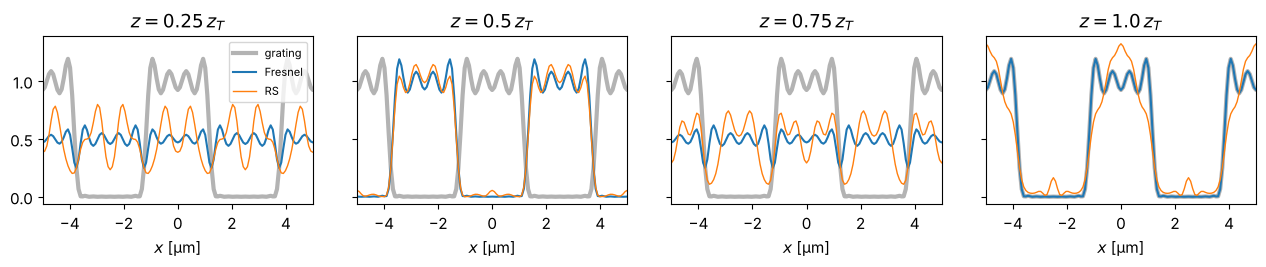

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(13, 2.8), sharey=True)
for ax, frac in zip(axes, (0.25, 0.5, 0.75, 1.0)):
    i = np.argmin(np.abs(z_vals - frac*z_T))
    ax.plot(xg, grating**2, color="0.7", lw=3, label="grating")
    ax.plot(xg, np.abs(carpet_F[i])**2, label="Fresnel")
    ax.plot(xg, np.abs(carpet_RS[i])**2, lw=1, label="RS")
    ax.set_xlim(-d, d); ax.set_title(f"$z = {frac}\\,z_T$"); ax.set_xlabel("$x$ [µm]")
axes[0].legend(fontsize=8)
fig.tight_layout()

## 3. When does the Fresnel approximation fail?

The Fresnel transfer function $\exp\left(ikz - i\pi\lambda z (f_x^2+f_y^2)\right)$ is
the Taylor expansion of $\exp(i k_z z)$ for small angles. It has two weaknesses:

1. For large spatial frequencies the phase is wrong; light travels at too large
   angles.
2. Frequencies $|f| > 1/\lambda$ are in reality **evanescent**, but in the Fresnel
   approximation they propagate without damping.

A slit only one wavelength wide makes both visible. The intensity is shown on a
logarithmic scale so that the light at large angles can be seen:
Rayleigh-Sommerfeld confines everything to a half space ($|\sin\theta| \le 1$),
whereas in the Fresnel approximation light escapes at "impossible" angles and the
field directly behind the slit is noisy.

The side lobes of the Fresnel calculation are striking: the far field of a slit
of width $b$ is $\mathrm{sinc}^2$ with its first zero at $\sin\theta = \lambda/b$.
For $b = \lambda$ this is exactly at $90°$, so the exact calculation has no side
lobes at all. The Fresnel approximation, however, equates $x/z = \tan\theta$ with
$\sin\theta$. The direction $\sin\theta = 1$ thus lands at $x = z$ instead of at
infinity, and the spatial frequencies beyond it (in reality evanescent) produce
side lobes that do not exist physically.

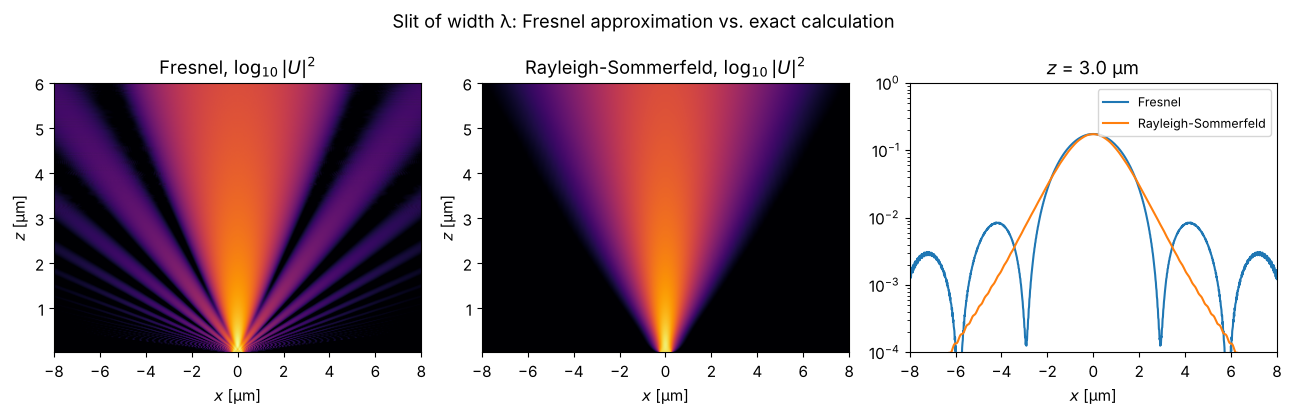

In [8]:
Ls, Ns = 60.0, 4096
xs = grid1d(-Ls/2, Ls/2, Ns)
slit = (np.abs(xs) <= wl/2).astype(float)   # width λ
z_vals_s = np.linspace(0.02, 6, 300)

U_F = xz_map(prop.fresnel_TF, slit, xs, z_vals_s, wl)
U_RS = xz_map(prop.rayleigh_sommerfeld_I_TF, slit, xs, z_vals_s, wl)

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, U, title in zip(axes, (U_F, U_RS), ("Fresnel", "Rayleigh-Sommerfeld")):
    ax.imshow(np.log10(np.abs(U)**2 + 1e-4), extent=(xs[0], xs[-1], z_vals_s[0], z_vals_s[-1]),
              aspect="auto", cmap="inferno", vmin=-3, vmax=0.3)
    ax.set_xlim(-8, 8); ax.set_xlabel("$x$ [µm]"); ax.set_ylabel("$z$ [µm]")
    ax.set_title(title + ", $\\log_{10}|U|^2$")
iz = np.argmin(np.abs(z_vals_s - 3))
axes[2].semilogy(xs, np.abs(U_F[iz])**2, label="Fresnel")
axes[2].semilogy(xs, np.abs(U_RS[iz])**2, label="Rayleigh-Sommerfeld")
axes[2].set_ylim(1e-4, 1)
axes[2].set_xlim(-8, 8); axes[2].set_xlabel("$x$ [µm]"); axes[2].set_title(f"$z$ = {z_vals_s[iz]:.1f} µm")
axes[2].legend(fontsize=9)
fig.suptitle("Slit of width λ: Fresnel approximation vs. exact calculation")
fig.tight_layout()

## 4. Evanescent waves

The exact transfer function $H(k_x) = \exp(i k_z z)$ with $k_z = \sqrt{k^2 - k_x^2}$
is a pure phase factor for $|k_x| < k$. For $|k_x| > k$, $k_z$ is imaginary and
`utils.k_z()` picks the branch $\mathrm{Im}\,k_z \ge 0$, so the wave decays:
$|H| = \exp(-\sqrt{k_x^2 - k^2}\, z)$.

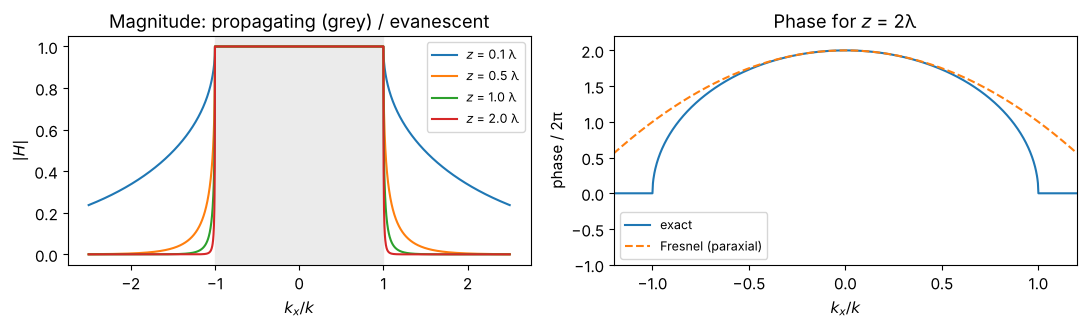

In [9]:
k = wavenumber(wl)
kx = np.linspace(-2.5*k, 2.5*k, 2001)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for z in (0.1*wl, 0.5*wl, wl, 2*wl):
    H = np.exp(1j*k_z(k, kx, 0)*z)
    axes[0].plot(kx/k, np.abs(H), label=f"$z$ = {z/wl:.1f} λ")
axes[0].set_xlabel("$k_x / k$"); axes[0].set_ylabel("$|H|$"); axes[0].legend(fontsize=9)
axes[0].axvspan(-1, 1, color="0.92", zorder=-1); axes[0].set_title("Magnitude: propagating (grey) / evanescent")
H = np.exp(1j*k_z(k, kx, 0)*2*wl)
axes[1].plot(kx/k, np.unwrap(np.angle(H))/(2*np.pi), label="exact")
axes[1].plot(kx/k, (k*2*wl - kx**2/(2*k)*2*wl)/(2*np.pi), "--", label="Fresnel (paraxial)")
axes[1].set_xlim(-1.2, 1.2); axes[1].set_ylim(-1, 2.2)
axes[1].set_xlabel("$k_x / k$"); axes[1].set_ylabel("phase / 2π"); axes[1].legend(fontsize=9)
axes[1].set_title("Phase for $z$ = 2λ")
fig.tight_layout()

A grating with period $d < \lambda$ has only evanescent diffraction orders apart
from the 0th. Its structure is therefore no longer visible just a few hundred
nanometres behind the grating: this is the reason for the resolution limit in the
far field (and the idea behind near-field microscopy). For $d > \lambda$, the
$\pm 1$st orders propagate at $\sin\theta = \lambda/d$ and produce a lasting
interference pattern.

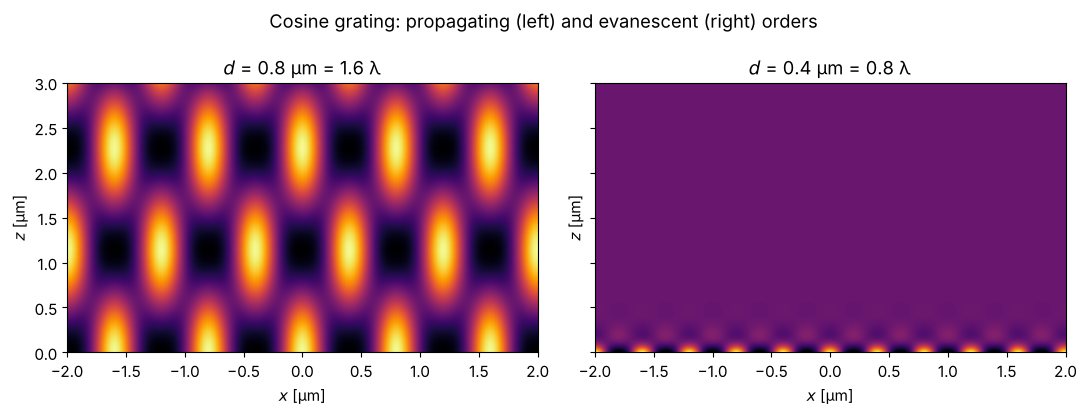

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
z_vals_e = np.linspace(0, 3, 300)
for ax, d_e in zip(axes, (0.8, 0.4)):
    Le, Ne = 20*d_e, 512
    xe = grid1d(-Le/2, Le/2, Ne)
    g = 1 + 0.8*np.cos(2*np.pi*xe/d_e)
    U = xz_map(prop.rayleigh_sommerfeld_I_TF, g, xe, z_vals_e, wl)
    plot_xz(ax, U, xe, z_vals_e, f"$d$ = {d_e} µm = {d_e/wl:.1f} λ", xlim=(-2, 2), vmax=3.3)
fig.suptitle("Cosine grating: propagating (left) and evanescent (right) orders")
fig.tight_layout()

## 5. Numerical pitfalls: wrap-around, sampling and aliasing

### Wrap-around
FFT convolutions are cyclic. Light that leaves the computational window on one
side re-enters on the other. An oblique Gaussian beam shows this. Zero padding
(for 2D fields: `propagate_padded()`) enlarges the window with zeros and crops the
result back to the original size.

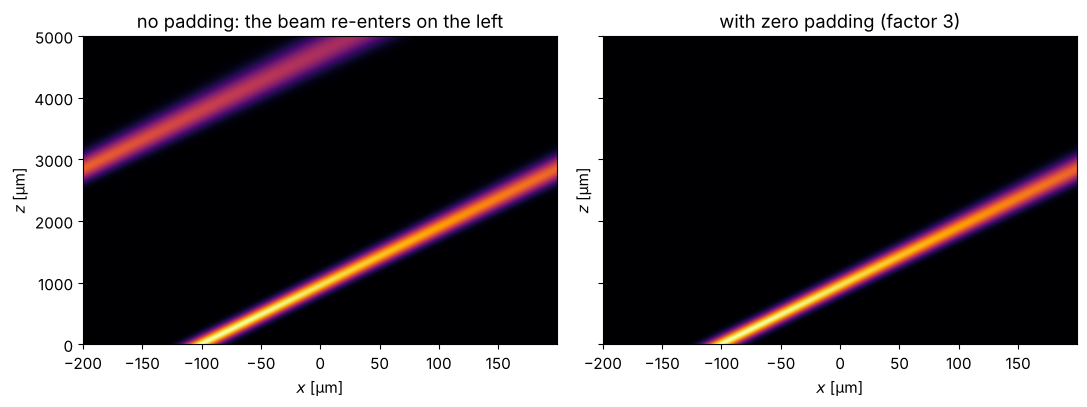

In [11]:
Lw, Nw = 400.0, 1024
xw = grid1d(-Lw/2, Lw/2, Nw)
theta = np.deg2rad(6)
beam = np.exp(-(xw + 100)**2/20**2)*np.exp(1j*k*np.sin(theta)*xw)
z_vals_w = np.linspace(0, 5000, 200)

U_nopad = xz_map(prop.rayleigh_sommerfeld_I_TF, beam, xw, z_vals_w, wl)

# For the 1D helper we pad in x only (propagate_padded() would also fill the two y
# rows with zeros and thus destroy the invariance in y):
pad = 3
xw_pad = grid1d(-pad*Lw/2, pad*Lw/2, pad*Nw)
beam_pad = np.zeros(pad*Nw, dtype=complex)
off = pad*Nw//2 - Nw//2
beam_pad[off:off + Nw] = beam
U_pad = xz_map(prop.rayleigh_sommerfeld_I_TF, beam_pad, xw_pad, z_vals_w, wl)[:, off:off + Nw]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
plot_xz(axes[0], U_nopad, xw, z_vals_w, "no padding: the beam re-enters on the left")
plot_xz(axes[1], U_pad, xw, z_vals_w, "with zero padding (factor 3)")
fig.tight_layout()

### Transfer function or impulse response?

Mathematically, convolution with the impulse response (IR) and multiplication
with the transfer function (TF) are identical; numerically they are not. The
Fresnel TF is a chirp in frequency, the IR a chirp in space. For a window width
$L$ and sampling distance $\Delta x$,

* the **TF** is well sampled for $z \le \Delta x\, L / \lambda$ (short distances),
* the **IR** is well sampled for $z \ge \Delta x\, L / \lambda$ (long distances).

Exactly at $\Delta x = \lambda z / L$ both are well sampled ("critical sampling",
see `suggest_N_critical()`). Section 1 chose the propagator by this criterion;
here we see what happens with the wrong choice.

critical distance z_crit = dx L / lambda = 1961 µm
suggest_N_critical(L, z_crit, wl) = 1001


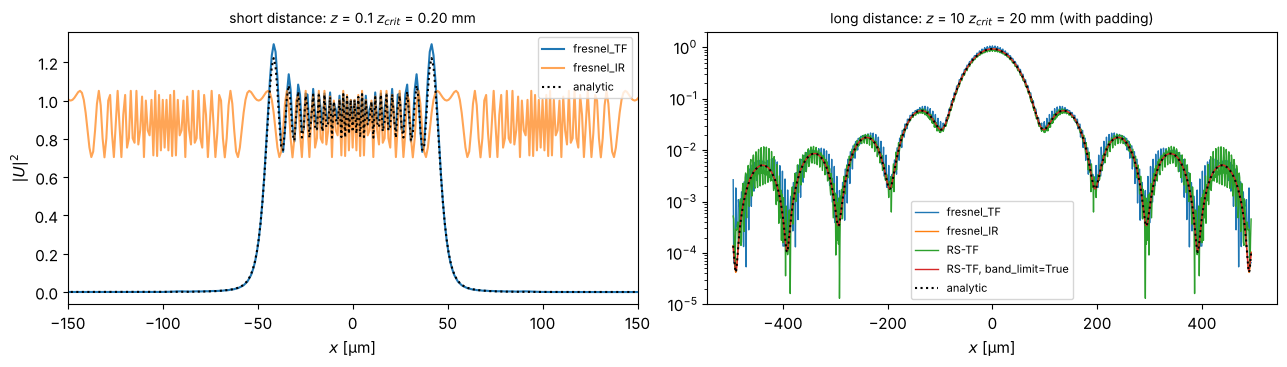

In [12]:
a_sq = 50.0
Nc = 1000
dxc = 2*a_sq/101          # edge again exactly between two samples
Lc = Nc*dxc
xc, yc, _, _ = grid2d(-Lc/2, Lc/2, -Lc/2, Lc/2, Nc)
square = rectangluar_mask(xc, yc, a_sq, a_sq).astype(complex)
z_crit = dxc*Lc/wl
print(f"critical distance z_crit = dx L / lambda = {z_crit:.0f} µm")
print("suggest_N_critical(L, z_crit, wl) =", prop.suggest_N_critical(Lc, z_crit, wl))

def I_square_ref(z):
    return 0.25*np.abs(fresnel_square_1d(xc, z, a_sq, wl))**2*np.abs(fresnel_square_1d(np.array([0.0]), z, a_sq, wl))**2

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
z = 0.1*z_crit
U_TF, _, _ = prop.fresnel_TF(square, xc, yc, z, wl)
U_IR, _, _ = prop.fresnel_IR(square, xc, yc, z, wl)
axes[0].plot(xc, np.abs(U_TF[Nc//2])**2, label="fresnel_TF")
axes[0].plot(xc, np.abs(U_IR[Nc//2])**2, label="fresnel_IR", alpha=0.7)
axes[0].plot(xc, I_square_ref(z), "k:", label="analytic")
axes[0].set_xlim(-150, 150); axes[0].set_xlabel("$x$ [µm]"); axes[0].set_ylabel("$|U|^2$")
axes[0].set_title(f"short distance: $z$ = 0.1 $z_{{crit}}$ = {z/1000:.2f} mm", fontsize=10)
axes[0].legend(fontsize=8, loc="upper right")

z = 10*z_crit
for propagator, kwargs, label in ((prop.fresnel_TF, {}, "fresnel_TF"),
                                   (prop.fresnel_IR, {}, "fresnel_IR"),
                                   (prop.rayleigh_sommerfeld_I_TF, {}, "RS-TF"),
                                   (prop.rayleigh_sommerfeld_I_TF, {"band_limit": True}, "RS-TF, band_limit=True")):
    U, _, _ = prop.propagate_padded(propagator, square, xc, yc, z, wl, pad_factor=2, **kwargs)
    axes[1].semilogy(xc, np.abs(U[Nc//2])**2, label=label, lw=1)
axes[1].semilogy(xc, I_square_ref(z), "k:", label="analytic")
axes[1].set_ylim(1e-5, 2); axes[1].set_xlabel("$x$ [µm]")
axes[1].set_title(f"long distance: $z$ = 10 $z_{{crit}}$ = {z/1000:.0f} mm (with padding)", fontsize=10)
axes[1].legend(fontsize=8, loc="lower center")
fig.tight_layout()

On the left, the impulse response is undersampled: `fresnel_IR` gives nonsense
outside the aperture, `fresnel_TF` is right. On the right it is the other way
round: the transfer functions (Fresnel and Rayleigh-Sommerfeld) produce noise in
the tails through aliasing, while the impulse response is clean.

For the exact transfer function $\exp(ik_z z)$ there is the **band-limited**
method of Matsushima and Shimobaba (`band_limit=True`): it sets to zero the
frequencies whose phase is no longer sampled correctly, and is used together with
padding. The noise disappears (red curve) without resorting to the paraxial
approximation.

## 6. Fraunhofer diffraction: the Airy disk

In the far field ($N_F \ll 1$) the diffraction pattern is the Fourier transform
of the aperture. `fraunhofer()` returns the field on the scaled grid
$x' = \lambda z f_x$. For a circular aperture of radius $a$ this gives the Airy
pattern

$$I(r) = I_0 \left(\frac{2 J_1(v)}{v}\right)^2, \qquad v = \frac{k a r}{z},$$

with the first zero at $r = 0.61\,\lambda z / a$.

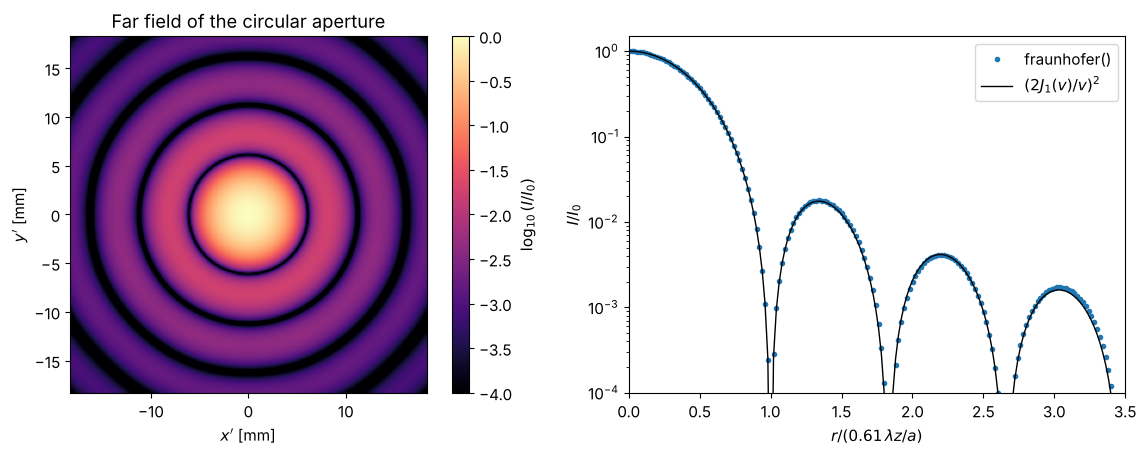

In [13]:
a_c = 50.0
Lf, Nf = 4096.0, 4096
xf, yf, Xf, Yf = grid2d(-Lf/2, Lf/2, -Lf/2, Lf/2, Nf)
disk = circular_mask(xf, yf, a_c).astype(complex)
zf = 1e6  # 1 m
Uf, xn, yn = prop.fraunhofer(disk, xf, yf, zf, wl)
If = np.abs(Uf)**2
If /= If.max()

r = np.abs(xn)
v = k*a_c*r/zf
airy = np.where(v == 0, 1.0, (2*j1(v)/np.where(v == 0, 1, v))**2)
r_zero = 0.61*wl*zf/a_c

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
c = 3*r_zero
sel = np.abs(xn) <= c
im = axes[0].imshow(np.log10(If[np.ix_(np.abs(yn) <= c, sel)] + 1e-6), extent=(-c/1000, c/1000, -c/1000, c/1000),
                    cmap="magma", vmin=-4)
fig.colorbar(im, ax=axes[0], label="$\\log_{10}(I/I_0)$")
axes[0].set_xlabel("$x'$ [mm]"); axes[0].set_ylabel("$y'$ [mm]"); axes[0].set_title("Far field of the circular aperture")
axes[1].semilogy(xn/r_zero, If[Nf//2], "o", ms=3, label="fraunhofer()")
axes[1].semilogy(xn/r_zero, airy, "k-", lw=1, label="$(2J_1(v)/v)^2$")
axes[1].set_xlim(0, 3.5); axes[1].set_ylim(1e-4, 1.5)
axes[1].set_xlabel("$r / (0.61\\,\\lambda z / a)$"); axes[1].set_ylabel("$I/I_0$"); axes[1].legend()
fig.tight_layout()

## 7. On-axis intensity behind a circular aperture

On the axis of a circular aperture, the Fresnel zones are exact rings of equal
area. Neighbouring zones cancel: for an odd number of zones the axis is bright
(up to $4 I_0$, twice the amplitude), for an even number it is dark ($I = 0$).
For Rayleigh-Sommerfeld theory there is a closed-form solution (Mahajan),
implemented in `analytical.mahajan_on_axis_intensity()`. The grey lines mark
$N_F = a^2/(\lambda z) = 1, 3, 5, 7$.

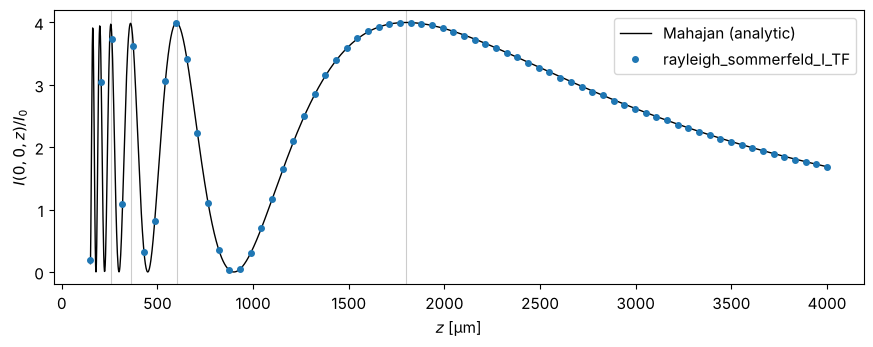

In [14]:
a_m = 30.0
Lm, Nm = 256.0, 512
xm, ym, _, _ = grid2d(-Lm/2, Lm/2, -Lm/2, Lm/2, Nm)
disk_m = circular_mask(xm, ym, a_m).astype(complex)

z_dense = np.linspace(150, 4000, 2000)
I_mahajan = mahajan_on_axis_intensity(a_m, 0.0, 1.0, wl, z_dense)
z_num = np.linspace(150, 4000, 70)
I_num = []
for z in z_num:
    U, _, _ = prop.propagate_padded(prop.rayleigh_sommerfeld_I_TF, disk_m, xm, ym, z, wl,
                                    pad_factor=2, band_limit=True)
    I_num.append(np.abs(U[Nm//2, Nm//2])**2)

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(z_dense, I_mahajan, "k-", lw=1, label="Mahajan (analytic)")
ax.plot(z_num, I_num, "o", ms=4, label="rayleigh_sommerfeld_I_TF")
for m in range(4):  # odd number of zones 2m+1 -> maximum
    ax.axvline(a_m**2/(wl*(2*m + 1)), color="0.8", lw=0.8, zorder=-1)
ax.set_xlabel("$z$ [µm]"); ax.set_ylabel("$I(0, 0, z) / I_0$"); ax.legend()
fig.tight_layout()

## 8. The Poisson spot

Behind an opaque disk, wave optics predicts a bright spot on the axis. Poisson
considered this absurd and hence an argument against Fresnel's theory; Arago then
found the spot experimentally. All edge waves travel the same distance to the
axis and interfere constructively. The plane wave is periodically continued here,
so the cyclic convolution is again correct.

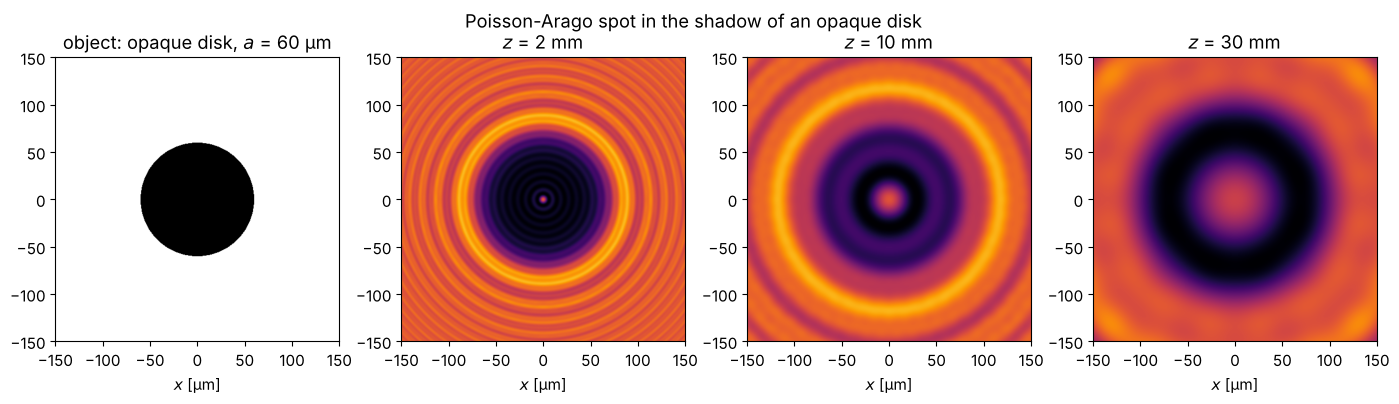

In [15]:
Lp, Np = 600.0, 1024
xp, yp, _, _ = grid2d(-Lp/2, Lp/2, -Lp/2, Lp/2, Np)
obstacle = 1.0 - circular_mask(xp, yp, 60.0)
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
axes[0].imshow(obstacle, extent=(xp[0], xp[-1], yp[0], yp[-1]), cmap="gray")
axes[0].set_title("object: opaque disk, $a$ = 60 µm")
for ax, z in zip(axes[1:], (2000, 10000, 30000)):
    U, _, _ = prop.rayleigh_sommerfeld_I_TF(obstacle.astype(complex), xp, yp, z, wl, band_limit=True)
    ax.imshow(np.abs(U)**2, extent=(xp[0], xp[-1], yp[0], yp[-1]), cmap="inferno", vmax=1.6)
    ax.set_title(f"$z$ = {z/1000:.0f} mm")
for ax in axes:
    ax.set_xlim(-150, 150); ax.set_ylim(-150, 150); ax.set_xlabel("$x$ [µm]")
fig.suptitle("Poisson-Arago spot in the shadow of an opaque disk")
fig.tight_layout()